# Exploration des consommations

Comprendre les données avant de choisir les entrées du modèle. **Un site, une heure ; cible : consumption_kwh.**

### Lancer le notebook

**Prérequis : Python 3.12 ou supérieur.** Depuis la racine du projet :

1. Récupérer le CSV combiné et le placer dans **.data/ml/raw/all_sites_combined.csv**. Le CSV est ignoré par Git : il ne sera pas présent après le clonage.
2. À la première utilisation, créer l'environnement Python dédié et installer les dépendances :

~~~bash
python3 -m venv services/ml-service/notebook/.venv
source services/ml-service/notebook/.venv/bin/activate
python -m pip install -r services/ml-service/requirements-notebooks.txt
~~~

3. Lancer JupyterLab :

~~~bash
python -m jupyterlab services/ml-service/notebook/01_exploration_consommation.ipynb
~~~

Pour les lancements suivants, réactiver l'environnement avec la commande **source** ci-dessus, puis relancer JupyterLab. Dans le notebook, choisir **Kernel → Restart Kernel and Run All Cells** pour recalculer les résultats.

Pour un CSV situé ailleurs, définir **ML_EXPLORATION_CSV** avant de lancer JupyterLab ; les chemins relatifs sont résolus depuis la racine du projet.

Convention choisie : **UTC+2 fixe**, timestamp au début de l'heure. Les tableaux et graphiques restent dans ce notebook. La section 6 génère uniquement les trois fichiers Parquet dans .data/ml/splits/, sans modifier le CSV ni entraîner de modèle.

In [1]:
from datetime import timedelta, timezone
from pathlib import Path
import hashlib
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display

%matplotlib inline
sns.set_theme(style="whitegrid", palette="colorblind")
pd.options.display.float_format = "{:.2f}".format

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "compose.yaml").is_file())
SOURCE = Path(os.environ.get("ML_EXPLORATION_CSV", ".data/ml/raw/all_sites_combined.csv")).expanduser()
SOURCE = SOURCE if SOURCE.is_absolute() else ROOT / SOURCE
source_hash = hashlib.sha256(SOURCE.read_bytes()).hexdigest()
raw = pd.read_csv(SOURCE)
df = raw.copy()
df["timestamp"] = pd.to_datetime(df["timestamp"]).dt.tz_localize(timezone(timedelta(hours=2)))
TARGET = "consumption_kwh"
SITES = sorted(df["site_id"].unique())

display(Markdown(f"**{len(df):,} lignes, {len(SITES)} sites**, du {df.timestamp.min():%d/%m/%Y %Hh} au {df.timestamp.max():%d/%m/%Y %Hh}."))
display(Markdown("**Colonnes :** " + ", ".join(raw.columns) + "."))

**122,647 lignes, 7 sites**, du 01/01/2023 00h au 31/12/2024 00h.

**Colonnes :** timestamp, site_id, site_type, site_name, consumption_kwh, consumption_euros, temperature_celsius, humidity_percent, solar_irradiance_wm2, hour, day_of_week, day_name, month, is_weekend, is_working_hours.

## 1. Qualité des données

Repérer les manquants, doublons, heures absentes et valeurs à examiner. Les champs vides restent distincts des zéros ; aucune valeur n'est corrigée.

In [2]:
missing = raw.isna().sum()
display(pd.DataFrame({
    "valeurs_manquantes": missing[missing.gt(0)],
    "pourcentage": missing[missing.gt(0)] / len(raw) * 100,
}))
duplicates = df.duplicated(["site_id", "timestamp"]).sum()
missing_hours = sum(
    len(pd.date_range(group.timestamp.min(), group.timestamp.max(), freq="h")) - group.timestamp.nunique()
    for _, group in df.groupby("site_id")
)
daily_hours = df.groupby(["site_id", df.timestamp.dt.date]).timestamp.nunique()
partial_days = daily_hours.lt(24).sum()
calendar_errors = (
    df.hour.ne(df.timestamp.dt.hour) | df.day_of_week.ne(df.timestamp.dt.dayofweek)
    | df.month.ne(df.timestamp.dt.month) | df.is_weekend.ne(df.timestamp.dt.dayofweek.ge(5).astype(int))
    | df.day_name.ne(df.timestamp.dt.day_name())
).sum()
display(Markdown(
    f"**Contrôles :** {duplicates} doublons site/heure ; {missing_hours} heures absentes entre les bornes de chaque site ; "
    f"{calendar_errors} lignes au calendrier incohérent ; {df[TARGET].lt(0).sum()} consommations négatives.\n\n"
    f"**À retenir :** {missing[TARGET]:,} consommations manquantes ({missing[TARGET] / len(raw):.2%}), "
    f"{df[TARGET].eq(0).sum():,} zéros et {partial_days} journées partiellement présentes. "
    "La dernière journée du fichier ne contient que son début : ne pas l'interpréter comme une journée complète. "
    "Les moyennes suivantes utilisent uniquement les valeurs disponibles, zéros inclus."
))

,valeurs_manquantes,pourcentage
consumption_kwh,2840,2.32
consumption_euros,2487,2.03
temperature_celsius,3416,2.79
humidity_percent,3423,2.79
solar_irradiance_wm2,3964,3.23


**Contrôles :** 0 doublons site/heure ; 0 heures absentes entre les bornes de chaque site ; 0 lignes au calendrier incohérent ; 0 consommations négatives.

**À retenir :** 2,840 consommations manquantes (2.32%), 1,792 zéros et 7 journées partiellement présentes. La dernière journée du fichier ne contient que son début : ne pas l'interpréter comme une journée complète. Les moyennes suivantes utilisent uniquement les valeurs disponibles, zéros inclus.

## 2. Différences entre sites

Comparer niveaux, dispersion, zéros et pics. Les points au-delà des moustaches servent au repérage ; ils ne prouvent pas une erreur de mesure.

,type,n_valides,moyenne,mediane,ecart_type,maximum,zeros,manquants_pct
site_id,,,,,,,,
SITE001,office,17110,112.74,86.73,62.01,1006.26,281,2.35
SITE002,factory,17114,616.65,479.06,345.56,3225.29,261,2.32
SITE003,datacenter,17114,860.31,826.50,218.37,2734.88,235,2.32
SITE004,retail,17116,265.03,209.32,147.26,1854.34,225,2.31
SITE005,hospital,17112,551.86,528.79,151.11,2471.61,272,2.33
SITE006,office,17123,110.73,86.52,56.49,595.84,233,2.27
SITE007,factory,17118,623.99,474.75,355.93,4599.76,285,2.30


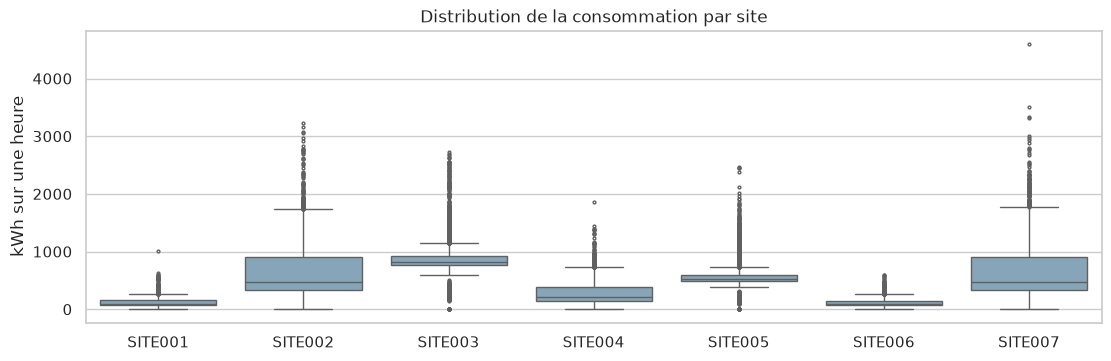

**Constat :** les moyennes vont de 110.73 à 860.31 kWh par heure observée. Le maximum atteint 4599.76 kWh.

**Conséquence :** évaluer les futurs résultats par site. Les zéros et pics nécessitent une vérification métier avant toute exclusion.

In [3]:
stats = df.groupby("site_id").agg(
    type=("site_type", "first"), n_valides=(TARGET, "count"), moyenne=(TARGET, "mean"),
    mediane=(TARGET, "median"), ecart_type=(TARGET, "std"), maximum=(TARGET, "max"),
    zeros=(TARGET, lambda values: values.eq(0).sum()),
)
stats["manquants_pct"] = (1 - stats.n_valides / df.groupby("site_id").size()) * 100
display(stats)
fig, ax = plt.subplots(figsize=(11, 3.5), layout="constrained")
sns.boxplot(data=df, x="site_id", y=TARGET, order=SITES, color="#7da7c2", fliersize=2, ax=ax)
ax.set(xlabel="", ylabel="kWh sur une heure", title="Distribution de la consommation par site")
plt.show()
plt.close(fig)
display(Markdown(
    f"**Constat :** les moyennes vont de {stats.moyenne.min():.2f} à {stats.moyenne.max():.2f} kWh par heure observée. "
    f"Le maximum atteint {df[TARGET].max():.2f} kWh.\n\n"
    "**Conséquence :** évaluer les futurs résultats par site. Les zéros et pics nécessitent une vérification métier avant toute exclusion."
))

## 3. Profils temporels

L'heure, le jour et le mois peuvent-ils expliquer les variations ? Comparer les profils séparément par site. Les courbes sont descriptives ; elles ne mesurent pas encore l'apport prédictif d'une variable.

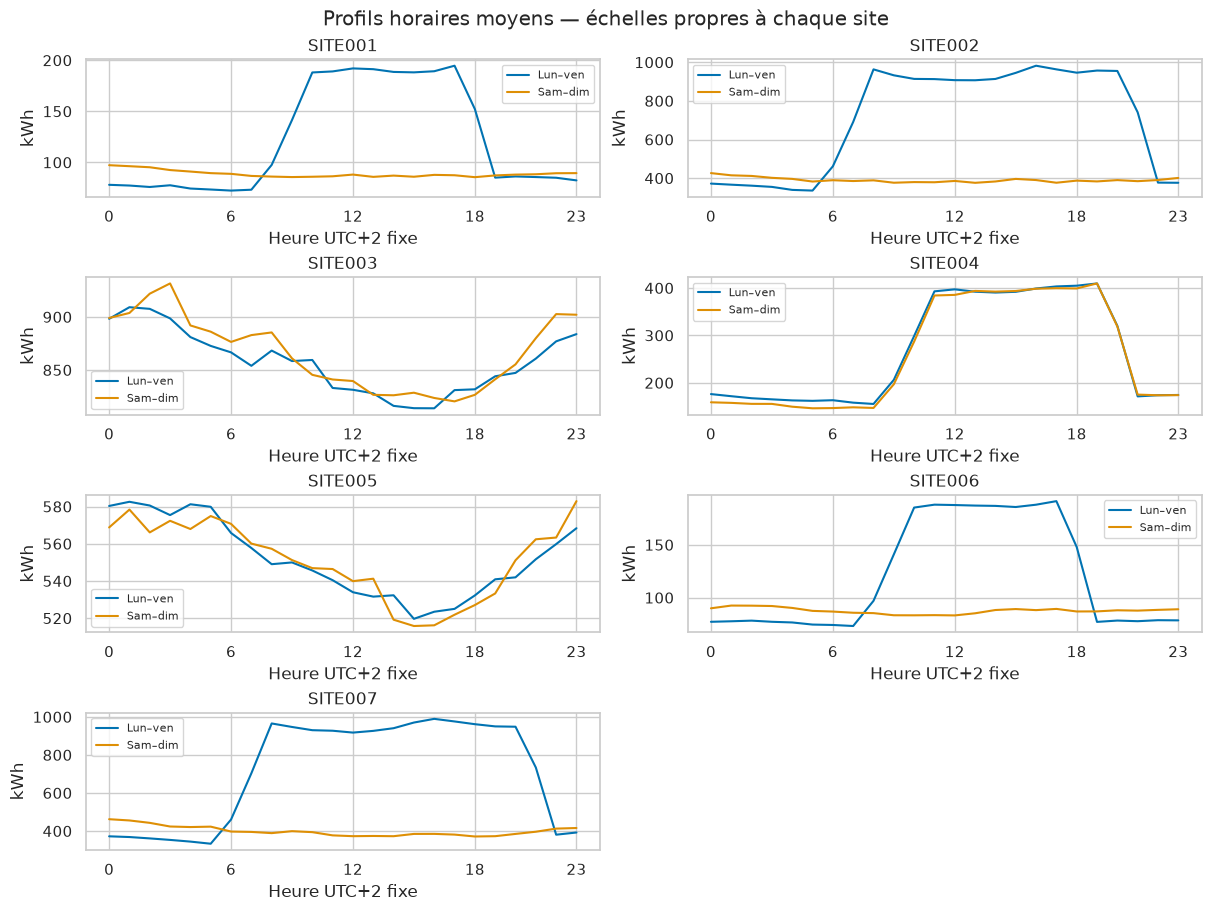

**Écart de moyenne week-end / semaine :** SITE001 : -27.4 % ; SITE002 : -44.8 % ; SITE003 : +1.1 % ; SITE004 : -2.6 % ; SITE005 : -0.1 % ; SITE006 : -27.0 % ; SITE007 : -44.0 %.

**À retenir :** les effets du calendrier diffèrent selon les sites.

In [4]:
hourly = df.groupby([
    "site_id", df.timestamp.dt.dayofweek.ge(5).rename("weekend"),
    df.timestamp.dt.hour.rename("heure"),
])[TARGET].agg(n="count", moyenne="mean").reset_index()
fig, axes = plt.subplots((len(SITES) + 1) // 2, 2, figsize=(12, 9), layout="constrained")
for site, ax in zip(SITES, np.asarray(axes).ravel()):
    for weekend, label in [(False, "Lun–ven"), (True, "Sam–dim")]:
        profile = hourly.loc[hourly.site_id.eq(site) & hourly.weekend.eq(weekend)]
        ax.plot(profile.heure, profile.moyenne, label=label)
    ax.set(title=site, xlabel="Heure UTC+2 fixe", ylabel="kWh", xticks=[0, 6, 12, 18, 23])
    ax.legend(fontsize=8)
for ax in np.asarray(axes).ravel()[len(SITES):]:
    ax.remove()
fig.suptitle("Profils horaires moyens — échelles propres à chaque site")
plt.show()
plt.close(fig)

weekend_means = df.groupby(["site_id", df.timestamp.dt.dayofweek.ge(5)])[TARGET].mean().unstack()
weekend_change = (weekend_means[True] / weekend_means[False] - 1) * 100
display(Markdown(
    "**Écart de moyenne week-end / semaine :** "
    + " ; ".join(f"{site} : {value:+.1f} %" for site, value in weekend_change.items())
    + ".\n\n**À retenir :** les effets du calendrier diffèrent selon les sites."
))

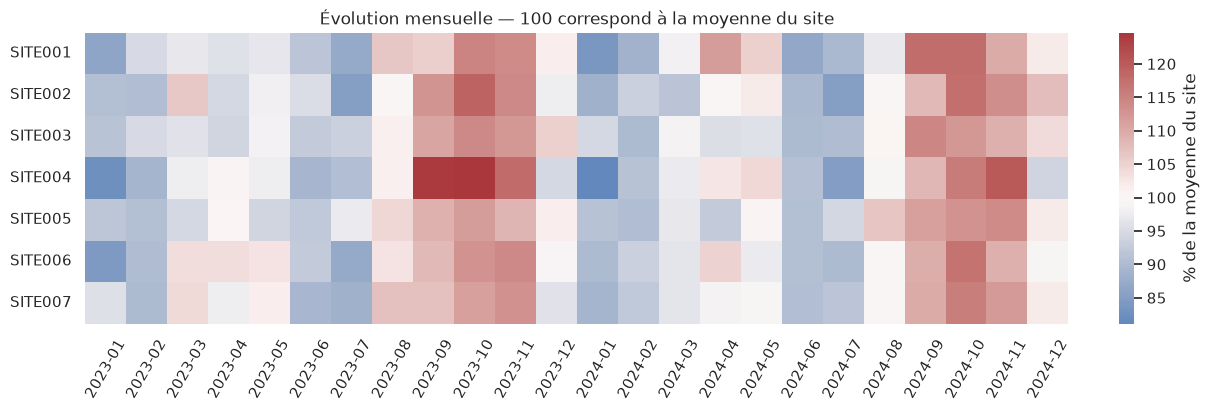

**Interprétation :** comparer les mêmes mois entre 2023 et 2024 pour examiner la répétition des variations. Le mois et l'heure restent des candidats à évaluer. Les moyennes n'inventent aucune valeur manquante ; elles ne représentent pas un total mensuel.

In [5]:
monthly = df.groupby(["site_id", df.timestamp.dt.strftime("%Y-%m").rename("mois")])[TARGET].agg(
    n="count", moyenne="mean",
).reset_index()
monthly["moyenne_relative_pct"] = monthly.moyenne / monthly.site_id.map(stats.moyenne) * 100
fig, ax = plt.subplots(figsize=(12, 4), layout="constrained")
sns.heatmap(monthly.pivot(index="site_id", columns="mois", values="moyenne_relative_pct"),
            cmap="vlag", center=100, cbar_kws={"label": "% de la moyenne du site"}, ax=ax)
ax.set(title="Évolution mensuelle — 100 correspond à la moyenne du site", xlabel="", ylabel="")
ax.tick_params(axis="x", rotation=60)
plt.show()
plt.close(fig)
display(Markdown(
    "**Interprétation :** comparer les mêmes mois entre 2023 et 2024 pour examiner la répétition des variations. "
    "Le mois et l'heure restent des candidats à évaluer. Les moyennes n'inventent aucune valeur manquante ; "
    "elles ne représentent pas un total mensuel."
))

## 4. Relations entre variables

Comparer les corrélations de Pearson par site et sur l'ensemble des sites. Chaque case indique la corrélation puis le nombre de paires disponibles. Une faible corrélation n'exclut pas une relation non linéaire ; une forte corrélation ne prouve ni causalité ni utilité pour la prévision.

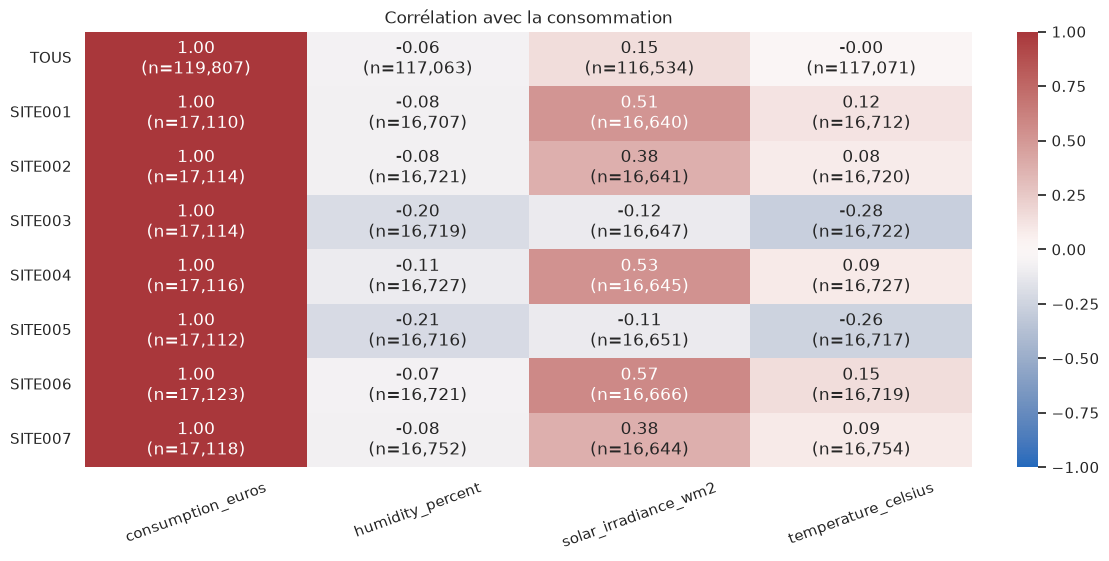

**Coût :** l'écart maximal avec 0,15 × kWh vaut 0.005500 €. Le coût observé est très proche de la cible et ne sera pas connu pour l'heure future : il faut l'écarter des entrées de cette prévision.

**Météo :** les relations varient selon les sites. La météo réellement observée pendant l'heure future n'est pas disponible au lancement ; son éventuel usage nécessiterait des prévisions météo.

In [6]:
variables = ["temperature_celsius", "humidity_percent", "solar_irradiance_wm2", "consumption_euros"]
records = []
for scope, group in [("TOUS", df), *list(df.groupby("site_id"))]:
    for variable in variables:
        pairs = group[[TARGET, variable]].dropna()
        records.append({"site": scope, "variable": variable, "n": len(pairs),
                        "correlation": pairs.corr().iloc[0, 1]})
relations = pd.DataFrame(records)
correlations = relations.pivot(index="site", columns="variable", values="correlation").reindex(["TOUS", *SITES])
counts = relations.pivot(index="site", columns="variable", values="n").reindex_like(correlations)
annotations = correlations.map(lambda value: f"{value:.2f}") + "\n(n=" + counts.map(lambda value: f"{value:,}") + ")"
fig, ax = plt.subplots(figsize=(11, 5.5), layout="constrained")
sns.heatmap(correlations, annot=annotations, fmt="", cmap="vlag", center=0, vmin=-1, vmax=1, ax=ax)
ax.set(title="Corrélation avec la consommation", xlabel="", ylabel="")
ax.tick_params(axis="x", rotation=20)
ax.tick_params(axis="y", rotation=0)
plt.show()
plt.close(fig)

cost_pairs = df[[TARGET, "consumption_euros"]].dropna()
cost_error = (cost_pairs.consumption_euros - .15 * cost_pairs[TARGET]).abs().max()
display(Markdown(
    f"**Coût :** l'écart maximal avec 0,15 × kWh vaut {cost_error:.6f} €. "
    "Le coût observé est très proche de la cible et ne sera pas connu pour l'heure future : "
    "il faut l'écarter des entrées de cette prévision.\n\n"
    "**Météo :** les relations varient selon les sites. La météo réellement observée pendant l'heure future "
    "n'est pas disponible au lancement ; son éventuel usage nécessiterait des prévisions météo."
))

## 5. Autocorrélation : 24 h, 7 jours et 30 jours

Comparer la consommation à celle du **même site**, à **t − 24 h**, **t − 168 h** et **t − 720 h**. Chaque valeur est une corrélation de Pearson entre ces deux consommations ; **n** indique le nombre de paires disponibles.

Les dates sont décalées exactement : aucune compression des heures ni imputation. Les paires contenant une valeur manquante sont écartées seulement après l'alignement ; les zéros restent présents. Trente jours ne représentent pas forcément le même jour de semaine.

lag,24 h,7 j,30 j
site,,,
SITE001,"0.446 (n=16,680)","0.590 (n=16,546)","0.284 (n=16,015)"
SITE002,"0.434 (n=16,686)","0.635 (n=16,551)","0.218 (n=16,009)"
SITE003,"0.148 (n=16,701)","0.177 (n=16,565)","0.118 (n=16,037)"
SITE004,"0.617 (n=16,695)","0.599 (n=16,556)","0.588 (n=16,031)"
SITE005,"0.121 (n=16,686)","0.099 (n=16,544)","0.079 (n=16,036)"
SITE006,"0.526 (n=16,720)","0.695 (n=16,562)","0.343 (n=16,054)"
SITE007,"0.404 (n=16,707)","0.605 (n=16,573)","0.199 (n=16,060)"


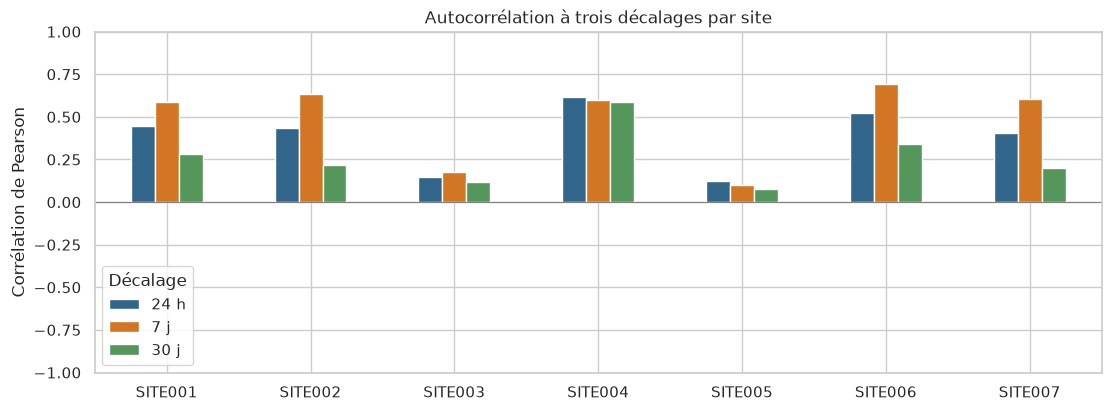

**Constats :** 7 jours présente la corrélation la plus élevée sur 5 sites sur 7, contre 2 pour 24 h et 0 pour 30 jours. Le décalage de 30 jours est le moins corrélé sur 7 sites. À 7 jours, les coefficients varient de 0.099 à 0.695.

**Proposition :** étudier en priorité 7 jours et 24 h comme entrées candidates, puis comparer leur apport réel au-delà du calendrier. Ces corrélations brutes, calculées avec des effectifs différents, peuvent refléter les cycles habituels ou une tendance ; elles ne démontrent pas encore un gain de prévision.

**Disponibilité :** ces trois lags peuvent être connus à 00 h 05 pour toutes les heures de la journée à prévoir, si l'historique correspondant est collecté. La future évaluation devra respecter cette heure de lancement.

In [7]:
LAGS = {"24 h": 24, "7 j": 168, "30 j": 720}
assert not df.duplicated(["site_id", "timestamp"]).any(), "Résoudre les doublons avant l'autocorrélation."
lag_records = []
for site, group in df.groupby("site_id"):
    series = group.set_index("timestamp")[TARGET].sort_index()
    for label, hours in LAGS.items():
        delayed = series.shift(freq=pd.Timedelta(hours=hours))
        pairs = pd.concat({"actuelle": series, "passee": delayed}, axis=1).dropna()
        lag_records.append({
            "site": site, "lag": label, "n_paires": len(pairs),
            "correlation": pairs.corr().loc["actuelle", "passee"],
        })
autocorrelations = pd.DataFrame(lag_records)
lag_correlations = autocorrelations.pivot(index="site", columns="lag", values="correlation").reindex(index=SITES, columns=LAGS)
lag_counts = autocorrelations.pivot(index="site", columns="lag", values="n_paires").reindex_like(lag_correlations)
lag_table = lag_correlations.map(lambda value: f"{value:.3f}") + " (n=" + lag_counts.map(lambda n: f"{n:,}") + ")"
display(lag_table)

fig, ax = plt.subplots(figsize=(11, 4), layout="constrained")
lag_correlations.plot.bar(ax=ax, rot=0, color=["#32658a", "#d27624", "#55965b"])
ax.axhline(0, color="grey", linewidth=.8)
ax.set(title="Autocorrélation à trois décalages par site", xlabel="", ylabel="Corrélation de Pearson", ylim=(-1, 1))
ax.legend(title="Décalage")
plt.show()
plt.close(fig)

lag_winners = lag_correlations.idxmax(axis=1).value_counts()
lag_30_lowest = lag_correlations["30 j"].eq(lag_correlations.min(axis=1)).sum()
display(Markdown(
    f"**Constats :** 7 jours présente la corrélation la plus élevée sur {lag_winners.get('7 j', 0)} sites sur {len(SITES)}, "
    f"contre {lag_winners.get('24 h', 0)} pour 24 h et {lag_winners.get('30 j', 0)} pour 30 jours. "
    f"Le décalage de 30 jours est le moins corrélé sur {lag_30_lowest} sites. "
    f"À 7 jours, les coefficients varient de {lag_correlations['7 j'].min():.3f} à {lag_correlations['7 j'].max():.3f}.\n\n"
    "**Proposition :** étudier en priorité 7 jours et 24 h comme entrées candidates, puis comparer leur apport réel "
    "au-delà du calendrier. Ces corrélations brutes, calculées avec des effectifs différents, peuvent refléter "
    "les cycles habituels ou une tendance ; elles ne démontrent pas encore un gain de prévision.\n\n"
    "**Disponibilité :** ces trois lags peuvent être connus à 00 h 05 pour toutes les heures de la journée à prévoir, "
    "si l'historique correspondant est collecté. La future évaluation devra respecter cette heure de lancement."
))

## 6. Jeux train, validation et test

Découpage chronologique identique pour les sept sites, selon l'heure cible en **UTC+2 fixe** :

| Fichier | Période |
| --- | --- |
| train.parquet | Du 1er janvier 2023 au 30 juin 2024 inclus |
| validation.parquet | Du 1er juillet au 30 septembre 2024 inclus |
| test.parquet | Du 1er octobre 2024 à la fin du CSV |

Les 15 colonnes d'origine sont conservées, avec **lag_24h** et **lag_168h**. Les lags sont calculés sur le même site et à la date exacte, **avant la séparation** : le début de validation peut ainsi utiliser l'historique de train, et le début du test celui de validation.

Les lignes où **consumption_kwh est NULL sont exclues des trois Parquet après le calcul des lags**, pour préserver les décalages horaires exacts. Les consommations à zéro sont conservées. Les NULL des autres colonnes et les premiers lags sans historique restent inchangés. La dernière journée incomplète reste dans test et devra être distinguée lors de l'évaluation par journées complètes.

Cette cellule crée seulement **.data/ml/splits/train.parquet**, **validation.parquet** et **test.parquet**, ignorés par Git. La relancer remplace ces trois fichiers. Le CSV reste intact ; aucun entraînement.

In [8]:
dataset = df.loc[:, raw.columns].sort_values(["timestamp", "site_id"]).reset_index(drop=True).copy()
assert not dataset.duplicated(["site_id", "timestamp"]).any(), "Clés site/heure dupliquées."
history = dataset.set_index(["site_id", "timestamp"])[TARGET]
for column, hours in {"lag_24h": 24, "lag_168h": 168}.items():
    previous_time = dataset.timestamp - pd.Timedelta(hours=hours)
    lookup = pd.MultiIndex.from_arrays([dataset.site_id, previous_time], names=history.index.names)
    dataset[column] = history.reindex(lookup).to_numpy()
    # L'heure historique est terminée avant le début de la journée à prévoir.
    assert (previous_time + pd.Timedelta(hours=1) <= dataset.timestamp.dt.normalize()).all()

# Filtrer la cible seulement après les lags ; les trous de l'historique restent à leur date.
excluded_target_times = dataset.loc[dataset[TARGET].isna(), "timestamp"]
dataset = dataset.dropna(subset=[TARGET]).reset_index(drop=True)
assert dataset[TARGET].notna().all()
assert len(dataset) + len(excluded_target_times) == len(raw)

periods = {
    "train": ("2023-01-01", "2024-07-01"),
    "validation": ("2024-07-01", "2024-10-01"),
    "test": ("2024-10-01", "2025-01-01"),
}
tz = dataset.timestamp.dt.tz
splits = {
    name: dataset.loc[
        dataset.timestamp.ge(pd.Timestamp(start, tz=tz))
        & dataset.timestamp.lt(pd.Timestamp(end, tz=tz))
    ].reset_index(drop=True)
    for name, (start, end) in periods.items()
}
# Vérifie l'ordre, l'absence de chevauchement et la conservation de toutes les lignes à cible connue.
pd.testing.assert_frame_equal(pd.concat(splits.values(), ignore_index=True), dataset)
assert all(set(part.site_id) == set(SITES) for part in splits.values())
assert hashlib.sha256(SOURCE.read_bytes()).hexdigest() == source_hash, "Le CSV a changé."

SPLIT_DIR = ROOT / ".data/ml/splits"
assert SOURCE.resolve() not in {(SPLIT_DIR / f"{name}.parquet").resolve() for name in splits}
SPLIT_DIR.mkdir(parents=True, exist_ok=True)
split_summary = []
for name, part in splits.items():
    assert part[TARGET].notna().all(), f"Cible NULL dans {name}."
    path = SPLIT_DIR / f"{name}.parquet"
    part.to_parquet(path, engine="pyarrow", compression="snappy", index=False)
    restored = pd.read_parquet(path, engine="pyarrow")
    restored["timestamp"] = restored.timestamp.dt.tz_convert(tz)
    pd.testing.assert_frame_equal(restored, part)
    split_summary.append({
        "jeu": name, "début": part.timestamp.min().strftime("%Y-%m-%d %Hh"),
        "fin": part.timestamp.max().strftime("%Y-%m-%d %Hh"), "lignes": len(part),
        "cibles_exclues": int((excluded_target_times.ge(pd.Timestamp(periods[name][0], tz=tz))
                               & excluded_target_times.lt(pd.Timestamp(periods[name][1], tz=tz))).sum()),
        "cibles_nulles": int(part[TARGET].isna().sum()),
        "lag_24h_nuls": int(part.lag_24h.isna().sum()),
        "lag_168h_nuls": int(part.lag_168h.isna().sum()),
    })
display(pd.DataFrame(split_summary).set_index("jeu"))
display(pd.DataFrame({name: part.groupby("site_id").size() for name, part in splits.items()}).rename_axis("lignes_par_site"))
display(Markdown(
    f"**Trois Parquet créés et relus : {len(dataset):,} lignes, {len(dataset.columns)} colonnes, "
    f"{len(SITES)} sites dans chaque fichier.** {len(excluded_target_times):,} cibles NULL exclues après le calcul des lags. "
    "Les zéros et les NULL des autres colonnes sont conservés. Aucun index ajouté, aucune imputation. "
    "Le 31 décembre 2024 ne contient qu'une heure par site et reste présent dans test."
))

,début,fin,lignes,cibles_exclues,cibles_nulles,lag_24h_nuls,lag_168h_nuls
jeu,,,,,,,
train,2023-01-01 00h,2024-06-30 23h,89780,2116,0,2233,3179
validation,2024-07-01 00h,2024-09-30 23h,15083,373,0,359,383
test,2024-10-01 00h,2024-12-31 00h,14944,351,0,340,348


,train,validation,test
lignes_par_site,,,
SITE001,12827,2124,2159
SITE002,12822,2150,2142
SITE003,12813,2172,2129
SITE004,12837,2141,2138
SITE005,12830,2173,2109
SITE006,12844,2146,2133
SITE007,12807,2177,2134


**Trois Parquet créés et relus : 119,807 lignes, 17 colonnes, 7 sites dans chaque fichier.** 2,840 cibles NULL exclues après le calcul des lags. Les zéros et les NULL des autres colonnes sont conservés. Aucun index ajouté, aucune imputation. Le 31 décembre 2024 ne contient qu'une heure par site et reste présent dans test.

## Conclusions pour la suite

Les décisions ci-dessous s'appuient sur les résultats précédents. Elles restent à confirmer avec le métier ou par une évaluation chronologique lors de l'entraînement.

In [9]:
conclusions = pd.DataFrame([
    ("Qualité", f"{missing[TARGET]:,} cibles manquantes ; {df[TARGET].eq(0).sum():,} zéros",
     "Exclure les cibles NULL des Parquet après le calcul des lags ; conserver les zéros"),
    ("Sites", f"Moyennes de {stats.moyenne.min():.2f} à {stats.moyenne.max():.2f} kWh",
     "Garder le site comme candidat et comparer les performances par site"),
    ("Calendrier", "Profils horaires, week-ends et variations mensuelles visibles ci-dessus",
     "Évaluer heure, jour et mois ; ne pas fixer définitivement les entrées maintenant"),
    ("Consommation passée", f"7 j le plus corrélé sur {lag_winners.get('7 j', 0)} sites ; 24 h sur {lag_winners.get('24 h', 0)}",
     "Lags 24 h et 7 j retenus pour les premiers essais ; 30 j reste une comparaison exploratoire"),
    ("Coût", f"Écart maximal avec 0,15 × kWh : {cost_error:.6f} €",
     "Écarter le coût observé de l'heure à prévoir pour éviter une fuite d'information"),
    ("Météo", "Corrélations différentes selon le site",
     "Étudier l'intérêt avec une météo disponible au moment de la prévision"),
    ("Heures travaillées", "La règle de is_working_hours n'est pas documentée",
     "Obtenir la règle ou le planning avant de l'utiliser pour une journée future"),
], columns=["sujet", "constat", "proposition"])
display(conclusions.style.hide(axis="index").set_properties(**{"text-align": "left", "white-space": "normal"}))
assert hashlib.sha256(SOURCE.read_bytes()).hexdigest() == source_hash, "Le CSV a changé."
display(Markdown(
    "**Périmètre :** entrées prévues : site_id, hour, day_of_week, month, lag_24h et lag_168h. "
    "UTC+2 fixe reste une convention à confirmer avant raccordement aux données de production. "
    "**CSV intact ; trois Parquet créés, aucun entraînement.**"
))

sujet,constat,proposition
Qualité,"2,840 cibles manquantes ; 1,792 zéros",Exclure les cibles NULL des Parquet après le calcul des lags ; conserver les zéros
Sites,Moyennes de 110.73 à 860.31 kWh,Garder le site comme candidat et comparer les performances par site
Calendrier,"Profils horaires, week-ends et variations mensuelles visibles ci-dessus","Évaluer heure, jour et mois ; ne pas fixer définitivement les entrées maintenant"
Consommation passée,7 j le plus corrélé sur 5 sites ; 24 h sur 2,Lags 24 h et 7 j retenus pour les premiers essais ; 30 j reste une comparaison exploratoire
Coût,"Écart maximal avec 0,15 × kWh : 0.005500 €",Écarter le coût observé de l'heure à prévoir pour éviter une fuite d'information
Météo,Corrélations différentes selon le site,Étudier l'intérêt avec une météo disponible au moment de la prévision
Heures travaillées,La règle de is_working_hours n'est pas documentée,Obtenir la règle ou le planning avant de l'utiliser pour une journée future


**Périmètre :** entrées prévues : site_id, hour, day_of_week, month, lag_24h et lag_168h. UTC+2 fixe reste une convention à confirmer avant raccordement aux données de production. **CSV intact ; trois Parquet créés, aucun entraînement.**